# Spectral Pact (Harakim)

Spectral Pact is a 180 s self buff. Every hit the caster takes is split before armor: 30–75% of
the raw damage is divided evenly among the caster's living ghost companions, and each share goes
through the companion's own `do_hurt` (its own armor and shields). The caster's armor then
applies to what is left.

| | |
|---|---|
| Class | Harakim |
| Target | Self (redirects to owned ghost companions) |
| Cost | 20 mana (not divided by 3 for Harakim) |
| Cooldown | none, but it cannot be recast while active (no refresh) |
| Landing roll | none |
| Duration | 180 s, or until no companion is left |
| Effect | `redirect = clamp(30 + ⌊45p/100⌋, 30, 75)` % of the raw `dam` in every `do_hurt` on the caster (not self-inflicted damage) |
| Source | `server/src/driver/skill/companion.rs::skill_spectral_pact`; redirect at the top of `server/src/state/stats.rs::do_hurt` |

---

# Formula

With $p$ the modified skill, $r$ the redirect percent, $n$ living companions and $d$ the raw damage
passed to `do_hurt`:

$$
r = \operatorname{clamp}\!\left(30 + \left\lfloor \tfrac{45p}{100} \right\rfloor,\ 30,\ 75\right)
\qquad
s = \left\lfloor \frac{\lfloor d\,r/100 \rfloor}{n} \right\rfloor
$$

$$
\text{owner HP} = k\cdot\max(0,\ d - n s - A_\text{owner})
\qquad
\text{each companion HP} = k\cdot\max(0,\ s - A_\text{comp})
$$

with $k = 0.25$ for melee (type 0) and $0.75$ for spells (types 1/2). The split happens
**before** armor, so the two pieces are mitigated separately. Together they lose
$k(d - A_\text{owner} - A_\text{comp})$: both armors count. The owner takes nothing at all while
$d - ns \le A_\text{owner}$, roughly $d \le A_\text{owner}/(1 - r)$, which is $4A_\text{owner}$
at the 75% cap.

| Quantity | Breakpoint |
|---|---|
| Ceiling | 75% from $p \ge 100$ (just below the raise cap of 105) |
| Floor | 30% for $p \le 1$ |
| Owner immune at the cap | raw hits up to about $4 \times$ armor |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
MANA_COST = 20
DURATION_S = 180

# Model

In [2]:
def redirect_pct(p):
    return mm.clamp(30 + mm.idiv(np.asarray(p) * 45, 100), 30, 75)


def split(dam, r, n=1):
    """(raw damage left on the owner, raw share per companion) for one `do_hurt`."""
    dam = np.asarray(dam)
    share = (dam * r // 100) // n
    return np.maximum(0, dam - n * share), share


def owner_hp(dam, r, owner_armor, n=1, kind=0):
    left, _ = split(dam, r, n)
    return mm.hurt_hp(left, owner_armor, kind)


def melee_owner_ratio(p, owner_armor, wv=60, strength=80, n=1):
    """Expected owner HP per landed melee hit with the pact / without it."""
    rolls = mm.melee_raw_rolls(wv, strength)
    base = np.mean(mm.hurt_hp(rolls, owner_armor))
    r = np.atleast_1d(redirect_pct(p))
    with_pact = np.array([np.mean(owner_hp(rolls, x, owner_armor, n)) for x in r])
    return with_pact / base if base > 0 else np.full(r.shape, np.nan)


def melee_companion_hp(p, comp_armor, wv=60, strength=80, n=1):
    """Expected HP each companion loses per landed melee hit on the owner."""
    rolls = mm.melee_raw_rolls(wv, strength)
    return np.array([np.mean(mm.hurt_hp(split(rolls, x, n)[1], comp_armor))
                     for x in np.atleast_1d(redirect_pct(p))])

# Validation

- `spectral_pact_sets_redirect_percent_and_cannot_stack`: skill 50 → 52%, the item lasts
  `TICKS*180`, mana 50,000 → 30,000; a second cast is refused and spends nothing.
- `spectral_pact_redirect_is_capped_below_full_damage`: skill 250 → 75%.

In [3]:
assert redirect_pct(50) == 52 and redirect_pct(250) == 75 and redirect_pct(0) == 30
assert 50_000 - MANA_COST * 1000 == 30_000 and mm.TICKS * DURATION_S == 6480
assert redirect_pct(99) == 74 and redirect_pct(100) == 75 and redirect_pct(105) == 75
assert split(100, 75) == (25, 75) and split(100, 75, 2) == (26, 37)
print("Spectral Pact model OK")

Spectral Pact model OK


# Plots

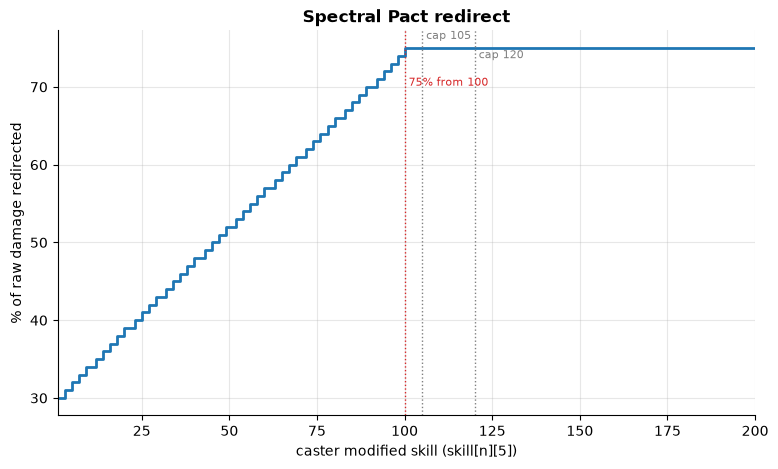

In [4]:
fig, ax = plt.subplots()
ax.step(P, redirect_pct(P), where="post")
mm.skill_axis(ax, "% of raw damage redirected", "Spectral Pact redirect")
mm.mark_caps(ax, extra=[(100, "75% from 100")])

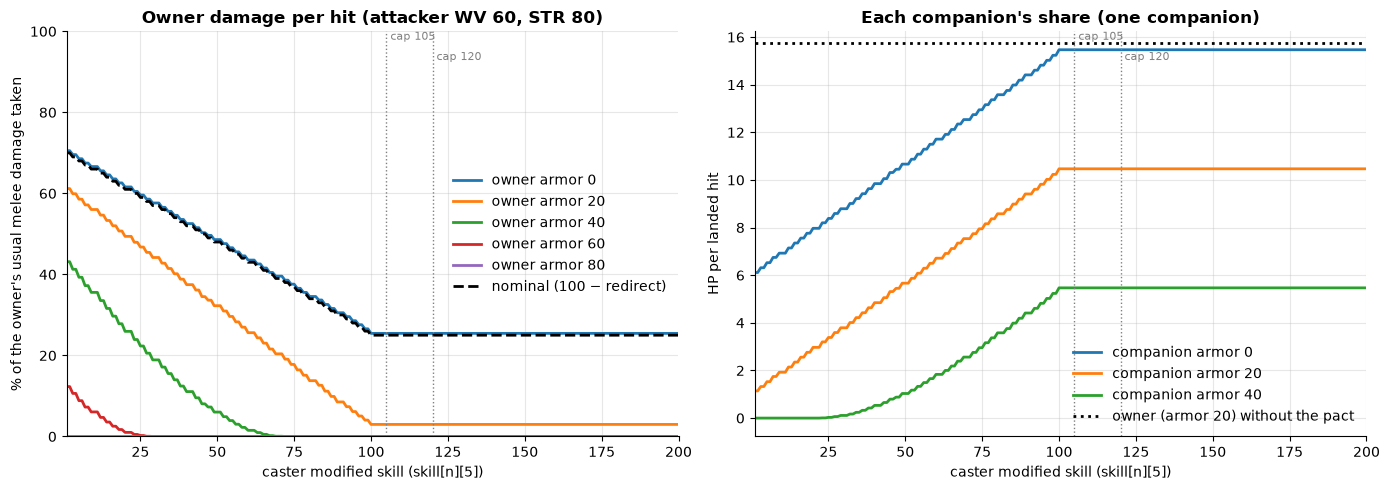

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for armor in mm.ARMOR_SWEEP:
    ax.plot(P, 100 * melee_owner_ratio(P, armor), label=f"owner armor {armor}")
ax.plot(P, 100 - redirect_pct(P), color="black", ls="--", label="nominal (100 − redirect)")
mm.skill_axis(ax, "% of the owner's usual melee damage taken", "Owner damage per hit (attacker WV 60, STR 80)")
ax.set_ylim(0, 100)
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
for comp_armor in (0, 20, 40):
    ax.plot(P, melee_companion_hp(P, comp_armor), label=f"companion armor {comp_armor}")
ax.axhline(np.mean(mm.hurt_hp(mm.melee_raw_rolls(60, 80), 20)), color="black", ls=":",
           label="owner (armor 20) without the pact")
mm.skill_axis(ax, "HP per landed hit", "Each companion's share (one companion)")
mm.mark_caps(ax)
ax.legend()
plt.tight_layout()

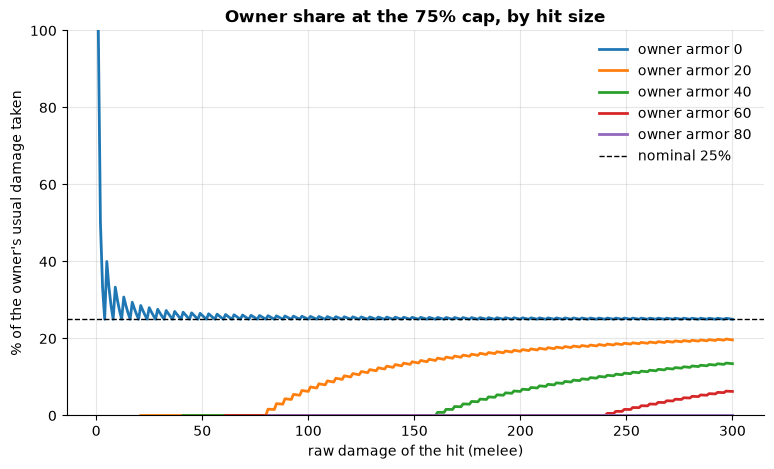

In [6]:
fig, ax = plt.subplots()
D = np.arange(1, 301)
for armor in mm.ARMOR_SWEEP:
    base = mm.hurt_hp(D, armor)
    with_pact = owner_hp(D, 75, armor)
    ax.plot(D, 100 * np.where(base > 0, with_pact / np.maximum(base, 1e-9), np.nan), label=f"owner armor {armor}")
ax.axhline(25, color="black", ls="--", lw=1, label="nominal 25%")
ax.set_xlabel("raw damage of the hit (melee)")
ax.set_ylabel("% of the owner's usual damage taken")
ax.set_title("Owner share at the 75% cap, by hit size")
ax.set_ylim(0, 100)
ax.legend()

# Observations

- **The split before armor makes the owner nearly immune.** With the cap reached at skill 100, an
  attacker with WV 60 and STR 80 (raw hits 61–105) deals 25% of its usual damage to an armor-0
  owner, as intended. Against armor 20 the owner takes only 3% (0.47 of 15.75 HP per hit), and from
  armor 40 nothing at all. Every raw hit up to about 4 × the owner's armor does no damage to the owner.
- **Damage leaves the system.** The companion's armor also applies to its share, so the pair loses
  less than one undefended target would. In the example above, with companion armor 20, the
  owner and the companion together lose 10.9 HP per hit instead of the owner's 15.75 (−31%). With
  companion armor 40 they lose 5.5 HP (−65%).
- **Saturates at skill 100.** 75% is reached just below the raise cap of 105, so the last raises
  add nothing.
- **The companion is the limit.** At Ghost 105 a companion has about 190 HP (475 with Revenant
  Conduit at its cap). It absorbs 10.5 HP per hit in the example above, so it lasts about 18 hits.
  When the last companion dies the pact is removed, and a new summon costs 45 mana plus a 20 mana
  recast. Revenant Conduit stacks with it: the larger companion lasts 2.5× longer and its own
  damage heals the owner.
- **Two companions split the share.** With Kindred Spirit the share is divided evenly, so each
  companion's armor applies to a smaller piece. More of the redirected damage is lost to armor,
  and the companions last more than twice as long.
- **Only `do_hurt` is redirected.** DoT ticks that write `a_hp` directly, such as the Lava Blast
  burn, bypass the pact. Hits too small to give each companion at least 1 raw point are not
  redirected.
- **No refresh.** A recast is refused while the pact is up, so there is a short gap every 180 s
  (20 mana per 3 minutes).
- **Balance suggestions.** Apply the owner's armor to the full hit first and split the
  post-armor damage, for example by redirecting a share of the `do_hurt` result rather than of
  the raw `dam`. That keeps the advertised 30–75% exact. Optionally spread the curve to
  `30 + 45p/150` so it caps at 150.